# Task 1: Data exploration (15%)
For this task you should *extract some insights* (i.e., some statistics and graphs) from the provided data.
It could be the length differences between two languages and also the number of sentences in the
whole corpus. Don’t limit yourself to these examples and try to find more insights in the data. Please
highlight some of the most important findings in your report.

Moreover, since the dataset is too large, randomly select 10% of data (data sampling) to train your
models on in the next steps.

Hint: if you faced codec errors in reading files, the “codecs” library could be used.

In [27]:
# %pip install pandas
# %pip install matplotlib
# %pip install numpy

In [ ]:
from pathlib import Path

# The dataset files are stored inside the "nl-en" subfolder
data_folder = Path("../data")

# Define the relative paths to the English and Dutch files
english_file = data_folder / "europarl-v7.nl-en.en"
dutch_file = data_folder / "europarl-v7.nl-en.nl"

# Check that both files can be found
print(english_file.exists())
print(dutch_file.exists())

True
True


In [29]:
# Read every English sentence into a list
with english_file.open("r", encoding="utf-8") as english_data:
    en = english_data.read().splitlines()

# Read every Dutch sentence into a list
with dutch_file.open("r", encoding="utf-8") as dutch_data:
    nl = dutch_data.read().splitlines()


print(f"english sentences: {len(en)}")
print(f"dutch sentences: {len(nl)}")

english sentences: 1997775
dutch sentences: 1997775


In [30]:
import pandas as pd

df = pd.DataFrame({'en': en, 'nl': nl})

df.sample(5, random_state=42)

,en,nl
1573507,The conduct of the municipal elections will be...,De plaatselijke verkiezingen worden een eerste...
502720,"The Council, too, though, when the situation f...","Maar ook de Raad heeft zich aanvankelijk, toen..."
668194,It is high time the Irish Government took back...,Het is de hoogste tijd dat de Ierse regering d...
951158,"Upon entry into force, the new regulation will...",Na de inwerkingtreding van de nieuwe verordeni...
641200,It is deeply shocking on a moral level that th...,Het is vanuit moreel oogpunt ronduit schokkend...


In [31]:
# count empty lines
print('empty lines:')
print((df['en'].str.strip() == '').sum())
print((df['nl'].str.strip() == '').sum())

# count lines with xml tags
print(df["en"].str.strip().str.startswith("<").sum())
print(df["nl"].str.strip().str.startswith("<").sum())

# count exact duplicate pairs
print('\nduplicate pairs:')
print(df.duplicated().sum())

empty lines:
15638
3392
0
0

duplicate pairs:
40320


0

duplicate pairs:


40320


In [32]:
# drop pairs where one side is empty, so they dont distort the statistics
df_clean = df[(df['en'].str.strip() != '') & (df['nl'].str.strip() != '')].copy()
print(f"pairs left: {len(df_clean)}")

pairs left: 1978745


In [33]:
df_clean['en_words'] = df_clean['en'].str.split().str.len()
df_clean['nl_words'] = df_clean['nl'].str.split().str.len()
df_clean['en_chars'] = df_clean['en'].str.len()
df_clean['nl_chars'] = df_clean['nl'].str.len()

df_clean[['en_words', 'nl_words', 'en_chars', 'nl_chars']].describe()

,en_words,nl_words,en_chars,nl_chars
count,1.978745e+06,1.978745e+06,1.978745e+06,1.978745e+06
mean,2.501701e+01,2.547940e+01,1.489238e+02,1.634862e+02
std,1.489954e+01,1.510229e+01,9.053808e+01,9.837258e+01
min,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
25%,1.400000e+01,1.500000e+01,8.500000e+01,9.300000e+01
50%,2.200000e+01,2.300000e+01,1.330000e+02,1.460000e+02
75%,3.300000e+01,3.300000e+01,1.940000e+02,2.140000e+02
max,6.680000e+02,5.830000e+02,3.950000e+03,3.889000e+03


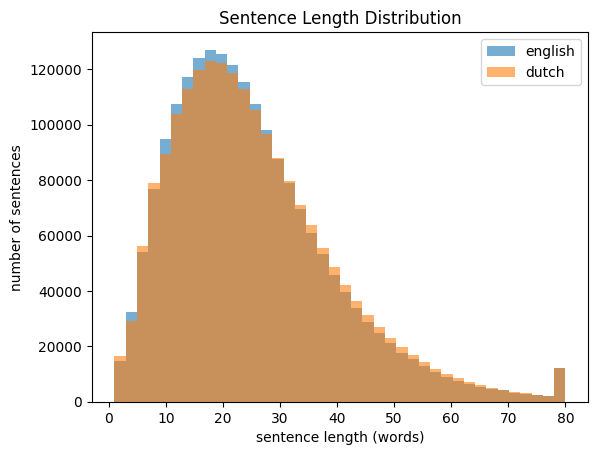

In [34]:
import matplotlib.pyplot as plt

# sentence length distribution, clipped at 80 words
plt.hist(df_clean['en_words'].clip(upper=80), bins=40, alpha=0.6, label='english')
plt.hist(df_clean['nl_words'].clip(upper=80), bins=40, alpha=0.6, label='dutch')
plt.xlabel('sentence length (words)')
plt.ylabel('number of sentences')
plt.title('Sentence Length Distribution')
plt.legend()

plt.savefig('task1_figure1', dpi=300, bbox_inches='tight')

plt.show()

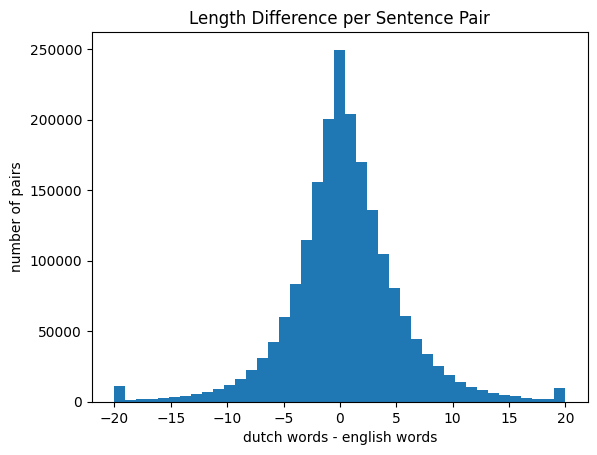

mean difference: 0.46
dutch longer: 47.69%
same length: 12.61%
correlation: 0.928


In [35]:
# how much longer is the dutch sentence of a pair
df_clean['diff'] = df_clean['nl_words'] - df_clean['en_words']

plt.hist(df_clean['diff'].clip(-20, 20), bins=41)
plt.xlabel('dutch words - english words')
plt.ylabel('number of pairs')
plt.title('Length Difference per Sentence Pair')

plt.savefig('task1_figure2', dpi=300, bbox_inches='tight')

plt.show()

print(f"mean difference: {df_clean['diff'].mean():.2f}")
print(f"dutch longer: {(df_clean['diff'] > 0).mean():.2%}")
print(f"same length: {(df_clean['diff'] == 0).mean():.2%}")
print(f"correlation: {df_clean['en_words'].corr(df_clean['nl_words']):.3f}")

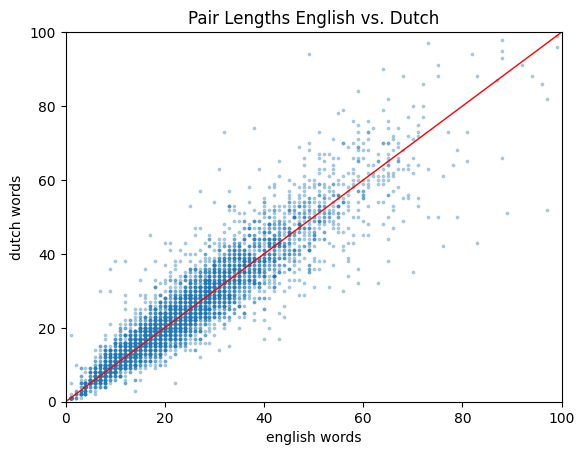

In [36]:
# scatter plot of pair lengths on a random sample
df_plot = df_clean.sample(5000, random_state=42)

plt.scatter(df_plot['en_words'], df_plot['nl_words'], s=3, alpha=0.3)
plt.plot([0, 100], [0, 100], color='red', linewidth=1)
plt.xlim(0, 100); plt.ylim(0, 100)
plt.xlabel('english words')
plt.ylabel('dutch words')
plt.title('Pair Lengths English vs. Dutch')

plt.savefig('task1_figure3', dpi=300, bbox_inches='tight')

plt.show()

In [37]:
# vocabulary size (lowercased, whitespace tokens)
from collections import Counter

freq_en = Counter()
for s in df_clean['en']:
    freq_en.update(s.lower().split())

freq_nl = Counter()
for s in df_clean['nl']:
    freq_nl.update(s.lower().split())

print(f"tokens en: {sum(freq_en.values())}")
print(f"tokens nl: {sum(freq_nl.values())}")
print(f"vocabulary size en: {len(freq_en)}")
print(f"vocabulary size nl: {len(freq_nl)}")

# words that appear only once
print(f"hapax en: {sum(1 for c in freq_en.values() if c == 1)}")
print(f"hapax nl: {sum(1 for c in freq_nl.values() if c == 1)}")

tokens en: 49502274
tokens nl: 50417243
vocabulary size en: 275650
vocabulary size nl: 495226
hapax en: 133995
hapax nl: 271086


In [38]:
freq_en.most_common(10)

[('the', 3789999),
 ('of', 1795471),
 ('to', 1666494),
 ('and', 1392572),
 ('in', 1174177),
 ('that', 864056),
 ('a', 837184),
 ('is', 819170),
 ('for', 575647),
 ('we', 569252)]

In [39]:
freq_nl.most_common(10)

[('de', 3830972),
 ('van', 2043056),
 ('het', 1713430),
 ('en', 1344366),
 ('in', 995876),
 ('een', 986320),
 ('dat', 981612),
 ('te', 724371),
 ('is', 619392),
 ('voor', 587840)]

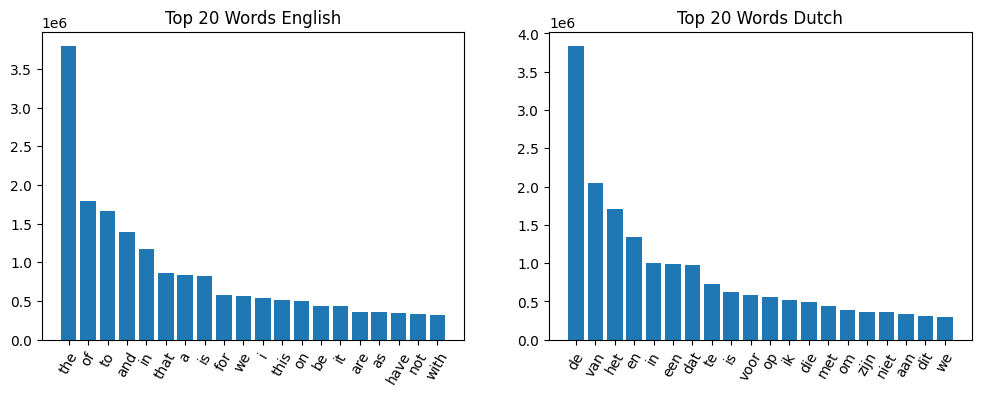

In [40]:
# top 20 words per language
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

words, counts = zip(*freq_en.most_common(20))
axes[0].bar(words, counts)
axes[0].tick_params(axis='x', rotation=60)
axes[0].set_title('Top 20 Words English')

words, counts = zip(*freq_nl.most_common(20))
axes[1].bar(words, counts)
axes[1].tick_params(axis='x', rotation=60)
axes[1].set_title('Top 20 Words Dutch')

plt.savefig('task1_figure4', dpi=300, bbox_inches='tight')

plt.show()

In [41]:
# how much of the text is covered by the top k words
import numpy as np

for name, freq in [('en', freq_en), ('nl', freq_nl)]:
    counts = np.sort(list(freq.values()))[::-1]
    total = counts.sum()
    for k in [100, 1000, 10000]:
        print(f"{name} top {k}: {counts[:k].sum() / total:.1%}")
    print()

en top 100: 52.1%
en top 1000: 75.7%
en top 10000: 94.8%

nl top 100: 53.6%
nl top 1000: 75.5%
nl top 10000: 92.5%



In [ ]:
import random
# Select 10% using the same method and seed as Task 2
sample_size = round(len(df) * 0.10)
random_generator = random.Random(42)

sampled_indices = random_generator.sample(
    range(len(df)),
    sample_size
)
# Restore the original corpus order
sampled_indices.sort()

df_sample = df.iloc[sampled_indices]

print("Sample size:", len(df_sample))

with open("../data/sample10.en", "w", encoding="utf-8") as english_output:
    english_output.write(
        "\n".join(df_sample["en"]) + "\n"
    )

with open("../data/sample10.nl", "w", encoding="utf-8") as dutch_output:
    dutch_output.write(
        "\n".join(df_sample["nl"]) + "\n"
    )
print(
    "Mean English length in full corpus:",
    round(df_clean["en_words"].mean(), 2)
)
print(
    "Mean English length in sample:",
    round(df_sample["en"].str.split().str.len().mean(), 2)
)

Sample size: 199778
Mean English length in full corpus: 25.02
Mean English length in sample: 24.81
